# Fine-tuning de Faster R-CNN para detección de vehículos UAV

datos → dataset → baseline COCO → transfer learning (cabeza) → fine-tuning parcial → fine-tuning completo


## 1. Imports y datos


In [1]:
import os
import kagglehub
import numpy as np
import pandas as pd
import torch
from PIL import Image
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from torchvision import tv_tensors
from torchvision.transforms import v2 as T
from torchvision.utils import draw_bounding_boxes
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn_v2,
    FasterRCNN_ResNet50_FPN_V2_Weights,
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

# Dispositivo y hiperparámetros (RTX 4070 Ti Super ~16 GB VRAM)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 8          # viable a 1920×1080 con backbone congelado + AMP
NUM_WORKERS = 4
NUM_CLASSES = 3 + 1     # 3 vehículos + fondo (índice 0)
print(f"Dispositivo: {device}")

# Descarga del dataset de la competencia
path = kagglehub.competition_download(
    "deteccion-de-vehiculos-en-imagenes-uav-en-colombia"
)
data_root = f"{path}/archive"
print("Datos en:", data_root)


/home/daniel/Dropbox/2026-02/Deep Learning/Semana 9/Competencia/.venv_u/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dispositivo: cuda
Datos en: /home/daniel/.cache/kagglehub/competitions/deteccion-de-vehiculos-en-imagenes-uav-en-colombia/archive


## 2. Dataset

Las anotaciones vienen en formato YOLO normalizado (`x_center, y_center, width, height`).
Las convertimos a cajas XYXY en píxeles, como espera Faster R-CNN.
Las etiquetas se desplazan `+1` porque torchvision reserva la clase `0` para fondo.


In [49]:
class CarDataset(Dataset):
    """Dataset de detección: imagen + diccionario {boxes, labels}."""

    def __init__(self, annotations_file, img_dir, transform=None):
        df = pd.read_csv(annotations_file)

        # YOLO normalizado → XYXY normalizado (vectorizado)
        x1 = df["x_center"] - df["width"] / 2
        y1 = df["y_center"] - df["height"] / 2
        x2 = df["x_center"] + df["width"] / 2
        y2 = df["y_center"] + df["height"] / 2
        df = df.assign(
            x1=x1, y1=y1, x2=x2, y2=y2,
            label=(df["class_id"].astype(int) + 1),  # +1 = fondo en Faster R-CNN
        )

        # Una entrada por imagen: (nombre, matriz N×5)
        self.samples = [
            (name, g[["x1", "y1", "x2", "y2", "label"]].to_numpy(np.float32))
            for name, g in df.groupby("image_id", sort=True)
        ]
        self.img_dir = img_dir
        self.transform = transform or T.Compose([
            T.ToImage(),
            T.ToDtype(torch.float32, scale=True),
        ])

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_name, arr = self.samples[idx]
        if not str(img_name).lower().endswith((".jpg", ".jpeg", ".png")):
            img_name = f"{img_name}.jpg"

        image = Image.open(os.path.join(self.img_dir, img_name)).convert("RGB")
        w, h = image.size

        boxes = torch.as_tensor(arr[:, :4], dtype=torch.float32)
        boxes[:, [0, 2]] *= w
        boxes[:, [1, 3]] *= h
        labels = torch.as_tensor(arr[:, 4], dtype=torch.int64)

        boxes = tv_tensors.BoundingBoxes(boxes, format="XYXY", canvas_size=(h, w))
        image, boxes = self.transform(image, boxes)

        return image, {"boxes": boxes, "labels": labels}


def collate_fn(batch):
    """Apila imágenes; deja targets como lista (N variable de cajas)."""
    images, targets = zip(*batch)
    return torch.stack(images), list(targets)


# Conjuntos de datos y loaders para train, validación y evaluación/test
train_ds = CarDataset(
    annotations_file=f"{data_root}/training/training_labels.csv",
    img_dir=f"{data_root}/training/images/",
)
val_ds = CarDataset(
    annotations_file=f"{data_root}/validation/validation_labels.csv",
    img_dir=f"{data_root}/validation/images/",
)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_fn,
)
val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_fn,
)

print(f"{len(train_ds)} imágenes de entrenamiento")


5680 imágenes de entrenamiento


## 3. Vista rápida de un lote


Lote: torch.Size([8, 3, 1080, 1920]) | cajas/img: [55, 73, 76, 49, 62, 51, 67, 79]


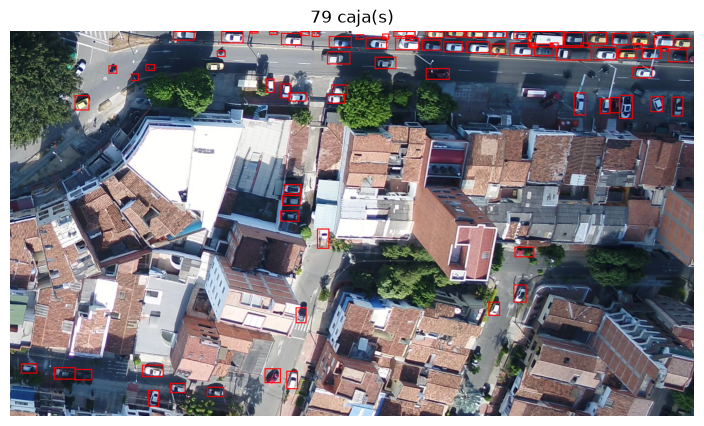

In [ ]:
images, targets = next(iter(train_loader))
print("Lote:", images.shape, "| cajas/img:", [t["boxes"].shape[0] for t in targets])

# Imagen con más detecciones del lote
idx = max(range(len(targets)), key=lambda i: targets[i]["boxes"].shape[0])
vis = draw_bounding_boxes(
    (images[idx] * 255).to(torch.uint8),
    boxes=targets[idx]["boxes"],
    labels=[str(int(x)) for x in targets[idx]["labels"]],
    colors="red",
    width=3,
)
fig, ax = plt.subplots(figsize=(9, 5))
ax.imshow(vis.permute(1, 2, 0).numpy())
ax.set_title(f"{len(targets[idx]['boxes'])} caja(s)")
ax.axis("off")
plt.show()

## 4. Baseline: inferencia con pesos COCO (sin fine-tuning)

Útil para ver qué detecta el modelo preentrenado antes de adaptarlo.


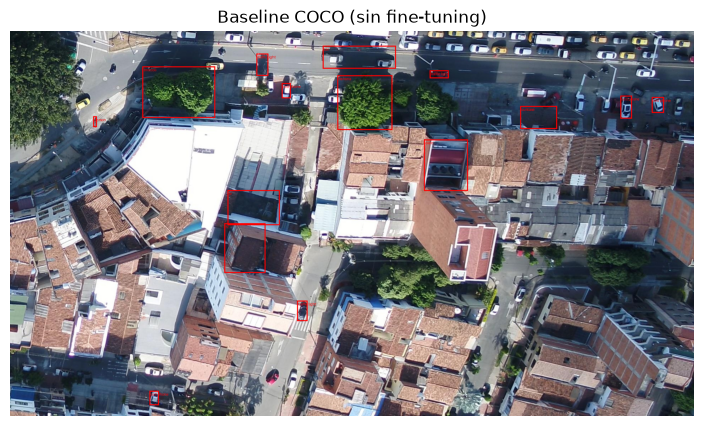

In [4]:
weights = FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1
baseline = fasterrcnn_resnet50_fpn_v2(weights=weights, box_score_thresh=0.7).eval()
preprocess = weights.transforms()

with torch.inference_mode():
    pred = baseline([preprocess(images[idx])])[0]

labels = [weights.meta["categories"][i] for i in pred["labels"]]
box_img = draw_bounding_boxes(
    (images[idx] * 255).to(torch.uint8),
    boxes=pred["boxes"],
    labels=labels,
    colors="red",
    width=3,
)
fig, ax = plt.subplots(figsize=(9, 5))
ax.imshow(box_img.permute(1, 2, 0).numpy())
ax.set_title("Baseline COCO (sin fine-tuning)")
ax.axis("off")
plt.show()

del baseline  # liberar VRAM antes del entrenamiento
torch.cuda.empty_cache()


## 5. Transfer learning: solo la cabeza de clasificación

Congelamos el backbone y reemplazamos `FastRCNNPredictor` para nuestras 3 clases + fondo.
Entrenamos con **AdamW** (mejor adaptación que SGD en fine-tuning) y **AMP**.


In [5]:
# Modelo preentrenado + nueva cabeza
model = fasterrcnn_resnet50_fpn_v2(weights=weights)
for p in model.parameters():
    p.requires_grad = False

in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_CLASSES)
model.to(device)

trainable = [n for n, p in model.named_parameters() if p.requires_grad]
print("Parámetros entrenables:", *trainable, sep="\n  ")

# AdamW: learning rate más alto solo en la cabeza nueva
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.AdamW(params, lr=1e-3, weight_decay=1e-4)
scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")


def train_one_epoch(model, loader, optimizer, scaler, device):
    model.train()
    total = 0.0
    for images, targets in loader:
        images = [img.to(device, non_blocking=True) for img in images]
        targets = [{k: v.to(device, non_blocking=True) for k, v in t.items()} for t in targets]

        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda", enabled=device.type == "cuda"):
            loss_dict = model(images, targets)
            loss = sum(loss_dict.values())

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total += loss.item()
    return total / max(len(loader), 1)


EPOCHS_HEAD = 5
for epoch in range(EPOCHS_HEAD):
    loss = train_one_epoch(model, train_loader, optimizer, scaler, device)
    print(f"Época {epoch + 1}/{EPOCHS_HEAD} — loss: {loss:.4f}")


Parámetros entrenables:
  roi_heads.box_predictor.cls_score.weight
  roi_heads.box_predictor.cls_score.bias
  roi_heads.box_predictor.bbox_pred.weight
  roi_heads.box_predictor.bbox_pred.bias


Época 1/5 — loss: 3.6277
Época 2/5 — loss: 3.5459
Época 3/5 — loss: 3.5281
Época 4/5 — loss: 3.5220
Época 5/5 — loss: 3.5145


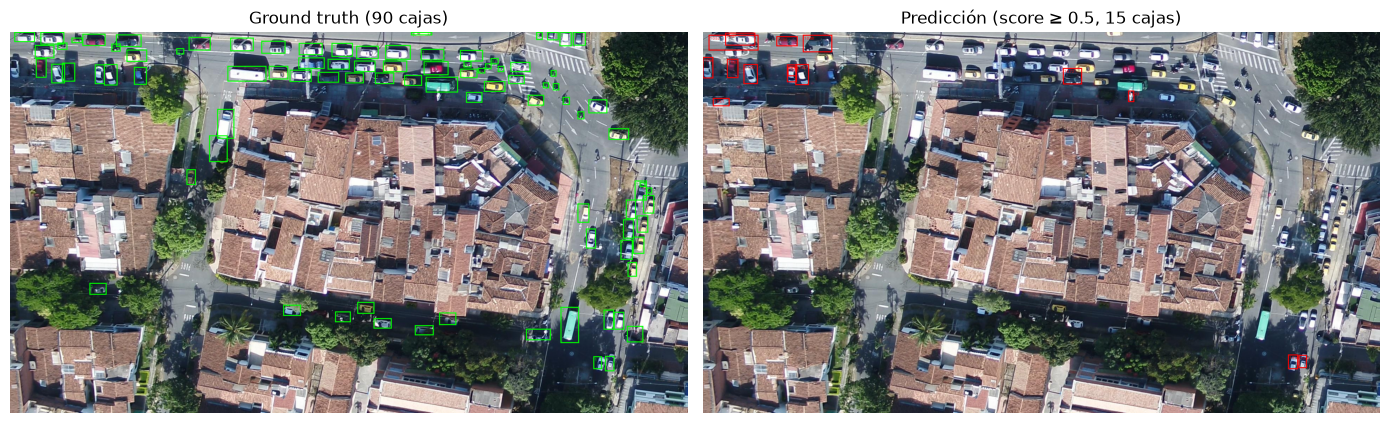

In [6]:
CLASS_NAMES = {1: "0", 2: "1", 3: "2"}
SCORE_THR = 0.5

model.eval()
images, targets = next(iter(train_loader))
idx = max(range(len(targets)), key=lambda i: targets[i]["boxes"].shape[0])
img = images[idx]

with torch.inference_mode(), torch.amp.autocast("cuda", enabled=device.type == "cuda"):
    pred = model([img.to(device)])[0]

keep = pred["scores"] >= SCORE_THR
pred_boxes = pred["boxes"][keep].cpu()
pred_labels = [
    f"{CLASS_NAMES.get(int(l), str(int(l)))} {s:.2f}"
    for l, s in zip(pred["labels"][keep].cpu(), pred["scores"][keep].cpu())
]
gt_labels = [CLASS_NAMES.get(int(l), str(int(l))) for l in targets[idx]["labels"]]

img_u8 = (img * 255).to(torch.uint8)
gt_vis = draw_bounding_boxes(img_u8, targets[idx]["boxes"], labels=gt_labels, colors="lime", width=3)
pred_vis = draw_bounding_boxes(img_u8, pred_boxes, labels=pred_labels, colors="red", width=3)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(gt_vis.permute(1, 2, 0).numpy())
axes[0].set_title(f"Ground truth ({len(targets[idx]['boxes'])} cajas)")
axes[0].axis("off")
axes[1].imshow(pred_vis.permute(1, 2, 0).numpy())
axes[1].set_title(f"Predicción (score ≥ {SCORE_THR}, {len(pred_boxes)} cajas)")
axes[1].axis("off")
plt.tight_layout()
plt.show()


## 6. Fine-tuning parcial: `box_head` + `layer4`

Descongelamos capas más profundas y bajamos el learning rate para no destruir features preentrenadas.


In [7]:
# Descongelar capas cercanas a la tarea
for name, p in model.named_parameters():
    if name.startswith("roi_heads.box_head") or name.startswith("backbone.body.layer4"):
        p.requires_grad = True

print("Entrenables ahora:", sum(p.requires_grad for p in model.parameters()), "tensores")

# LR más bajo al actualizar features preentrenadas
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.AdamW(params, lr=1e-4, weight_decay=1e-4)
# Batch más chico si VRAM se satura al descongelar layer4
train_loader_ft = DataLoader(
    train_ds,
    batch_size=max(2, BATCH_SIZE // 2),
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_fn,
)

EPOCHS_FT = 10
for epoch in range(EPOCHS_FT):
    loss = train_one_epoch(model, train_loader_ft, optimizer, scaler, device)
    print(f"Época {epoch + 1}/{EPOCHS_FT} — loss: {loss:.4f}")


Entrenables ahora: 48 tensores
Época 1/10 — loss: 0.6333
Época 2/10 — loss: 0.4543
Época 3/10 — loss: 0.3896
Época 4/10 — loss: 0.3479
Época 5/10 — loss: 0.3177
Época 6/10 — loss: 0.2939
Época 7/10 — loss: 0.2777
Época 8/10 — loss: 0.2636
Época 9/10 — loss: 0.2530
Época 10/10 — loss: 0.2430


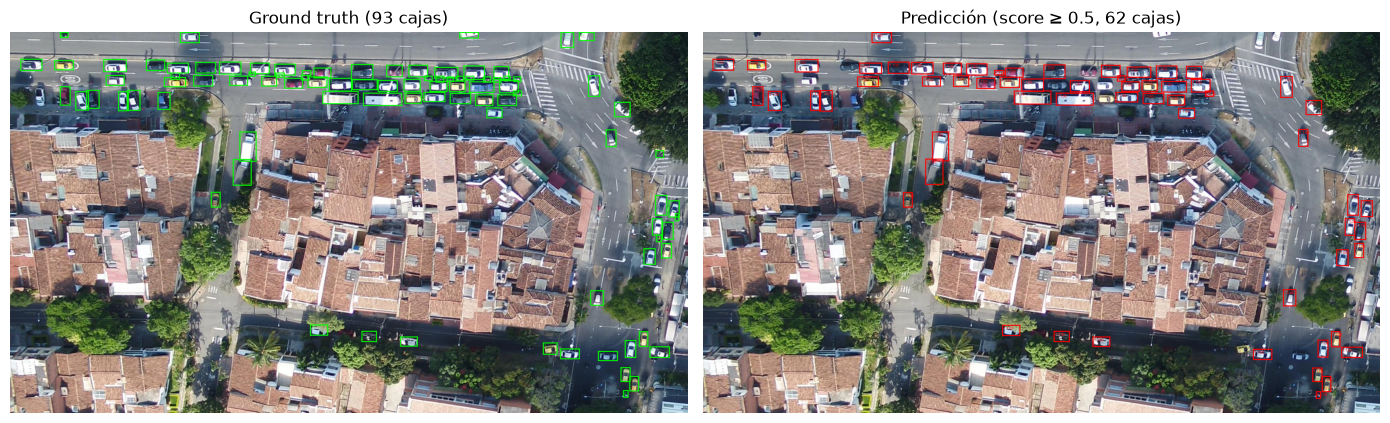

In [9]:
CLASS_NAMES = {1: "0", 2: "1", 3: "2"}
SCORE_THR = 0.5

model.eval()
images, targets = next(iter(train_loader))
idx = max(range(len(targets)), key=lambda i: targets[i]["boxes"].shape[0])
img = images[idx]

with torch.inference_mode(), torch.amp.autocast("cuda", enabled=device.type == "cuda"):
    pred = model([img.to(device)])[0]

keep = pred["scores"] >= SCORE_THR
pred_boxes = pred["boxes"][keep].cpu()
pred_labels = [
    f"{CLASS_NAMES.get(int(l), str(int(l)))} {s:.2f}"
    for l, s in zip(pred["labels"][keep].cpu(), pred["scores"][keep].cpu())
]
gt_labels = [CLASS_NAMES.get(int(l), str(int(l))) for l in targets[idx]["labels"]]

img_u8 = (img * 255).to(torch.uint8)
gt_vis = draw_bounding_boxes(img_u8, targets[idx]["boxes"], labels=gt_labels, colors="lime", width=3)
pred_vis = draw_bounding_boxes(img_u8, pred_boxes, labels=pred_labels, colors="red", width=3)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(gt_vis.permute(1, 2, 0).numpy())
axes[0].set_title(f"Ground truth ({len(targets[idx]['boxes'])} cajas)")
axes[0].axis("off")
axes[1].imshow(pred_vis.permute(1, 2, 0).numpy())
axes[1].set_title(f"Predicción (score ≥ {SCORE_THR}, {len(pred_boxes)} cajas)")
axes[1].axis("off")
plt.tight_layout()
plt.show()


## 7. Fine-tuning completo (todas las capas)

Descongelamos **todo** el modelo y entrenamos pocas épocas con LR aún más bajo.
Útil para adaptar features tempranas al dominio UAV; 2 épocas suelen bastar sin sobreajustar.

In [12]:
# Descongelar todas las capas
for p in model.parameters():
    p.requires_grad = True

print("Entrenables ahora:", sum(p.requires_grad for p in model.parameters()), "tensores")

# LR muy bajo: actualizamos pesos preentrenados de punta a punta
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.AdamW(params, lr=1e-5, weight_decay=1e-4)
# Batch pequeño: todo el backbone en gradientes + imágenes 1920×1080
train_loader_full = DataLoader(
    train_ds,
    batch_size=1,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_fn,
)

EPOCHS_FULL = 10
for epoch in range(EPOCHS_FULL):
    loss = train_one_epoch(model, train_loader_full, optimizer, scaler, device)
    print(f"Época {epoch + 1}/{EPOCHS_FULL} — loss: {loss:.4f}")


Entrenables ahora: 209 tensores
Época 1/10 — loss: 0.1443
Época 2/10 — loss: 0.1328
Época 3/10 — loss: 0.1250
Época 4/10 — loss: 0.1174
Época 5/10 — loss: 0.1112
Época 6/10 — loss: 0.1070
Época 7/10 — loss: 0.1019
Época 8/10 — loss: 0.0982
Época 9/10 — loss: 0.0957
Época 10/10 — loss: 0.0922


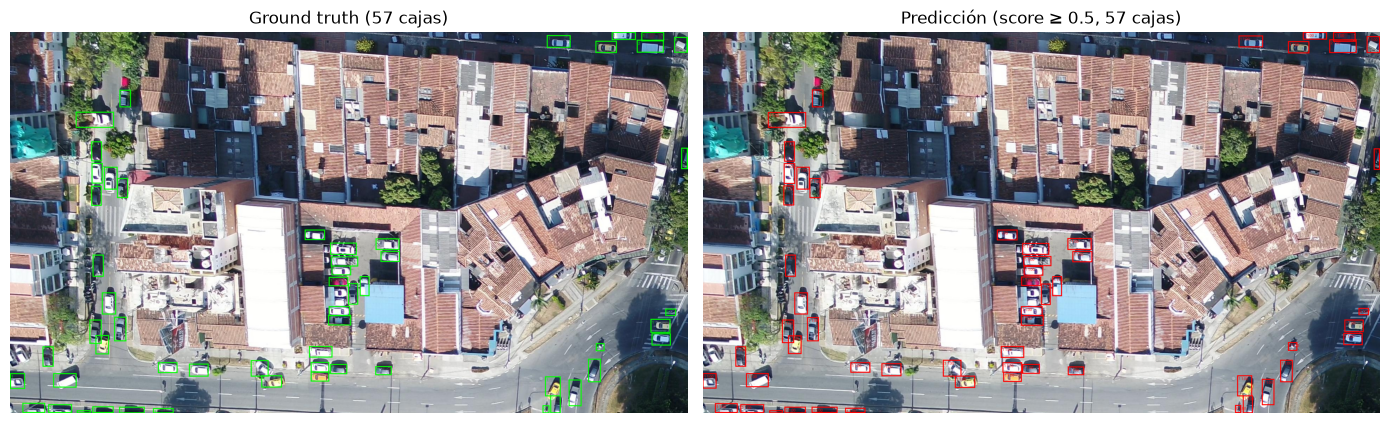

In [63]:
CLASS_NAMES = {1: "0", 2: "1", 3: "2"}
SCORE_THR = 0.5

model.eval()
images, targets = next(iter(train_loader_full))
idx=0
img = images[idx]

with torch.inference_mode(), torch.amp.autocast("cuda", enabled=device.type == "cuda"):
    pred = model([img.to(device)])[0]

keep = pred["scores"] >= SCORE_THR
pred_boxes = pred["boxes"][keep].cpu()
pred_labels = [
    f"{CLASS_NAMES.get(int(l), str(int(l)))} {s:.2f}"
    for l, s in zip(pred["labels"][keep].cpu(), pred["scores"][keep].cpu())
]
gt_labels = [CLASS_NAMES.get(int(l), str(int(l))) for l in targets[idx]["labels"]]

img_u8 = (img * 255).to(torch.uint8)
gt_vis = draw_bounding_boxes(img_u8, targets[idx]["boxes"], labels=gt_labels, colors="lime", width=3)
pred_vis = draw_bounding_boxes(img_u8, pred_boxes, labels=pred_labels, colors="red", width=3)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(gt_vis.permute(1, 2, 0).numpy())
axes[0].set_title(f"Ground truth ({len(targets[idx]['boxes'])} cajas)")
axes[0].axis("off")
axes[1].imshow(pred_vis.permute(1, 2, 0).numpy())
axes[1].set_title(f"Predicción (score ≥ {SCORE_THR}, {len(pred_boxes)} cajas)")
axes[1].axis("off")
plt.tight_layout()
plt.show()
